# Conclusion

Muhammad Sarab Aftab, Saurya Jonchhe, Nipun Yonjan

So this is where I compare the three models we tuned. Mine is the decision tree, Saurya did logistic regression, and Nipun did the linear SVM. I am fitting them again on the training data with the settings the searches picked, and then checking them on the test split. We left those test rows alone until now.


Before I look at our scores, I want to say what we were aiming for. The paper for this dataset says their random forest and their MiniLM plus logistic regression both get accuracy above 96% and ROC AUC above 0.99. Link: https://pmc.ncbi.nlm.nih.gov/articles/PMC12552964/

Their file has 111,660 URLs and ours has 116,600, so I am just using those numbers as the goal we wanted to get close to.


First I am loading the same split we have been using the whole time.


In [1]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier

from dataset_preparation import build_preparation_pipeline, prepare_datasets

data = prepare_datasets()

print("Train rows:", len(data["y_train"]))
print("Test rows:", len(data["y_test"]))
print("Test phishing rate:", round(float(data["y_test"].mean()), 4))


Train rows: 69138
Test rows: 23047
Test phishing rate: 0.144


These are the three settings we ended up with. I am treating phishing as the class we care about. The SVM does not give probabilities, so I am using its decision function for ROC AUC.


In [2]:
models = {
    "Decision tree": DecisionTreeClassifier(
        criterion="entropy",
        max_depth=16,
        min_samples_split=2,
        min_samples_leaf=1,
        max_features=None,
        class_weight=None,
        random_state=42,
    ),
    "Logistic regression": LogisticRegression(
        penalty="l2",
        C=10.0,
        solver="lbfgs",
        class_weight=None,
        max_iter=2000,
        random_state=42,
    ),
    "Linear SVM": LinearSVC(
        penalty="l2",
        loss="squared_hinge",
        dual=False,
        C=10.0,
        class_weight=None,
        max_iter=5000,
        random_state=42,
    ),
}

def test_scores(model, X, y):
    predictions = model.predict(X)
    if hasattr(model, "predict_proba"):
        ranking = model.predict_proba(X)[:, 1]
    else:
        ranking = model.decision_function(X)
    return {
        "accuracy": accuracy_score(y, predictions),
        "precision": precision_score(y, predictions, pos_label=1, zero_division=0),
        "recall": recall_score(y, predictions, pos_label=1, zero_division=0),
        "f1": f1_score(y, predictions, pos_label=1, zero_division=0),
        "roc_auc": roc_auc_score(y, ranking),
    }

results = {}
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", category=RuntimeWarning)
    for name, classifier in models.items():
        pipeline = Pipeline(
            steps=[
                ("prepare", build_preparation_pipeline()),
                ("model", classifier),
            ]
        )
        pipeline.fit(data["X_train"], data["y_train"])
        results[name] = test_scores(pipeline, data["X_test"], data["y_test"])

comparison = pd.DataFrame(results).round(4)
comparison


,Decision tree,Logistic regression,Linear SVM
accuracy,0.9760,0.9547,0.9536
precision,0.9279,0.9093,0.9213
recall,0.9033,0.7616,0.7411
f1,0.9154,0.8289,0.8214
roc_auc,0.9523,0.9760,0.9757


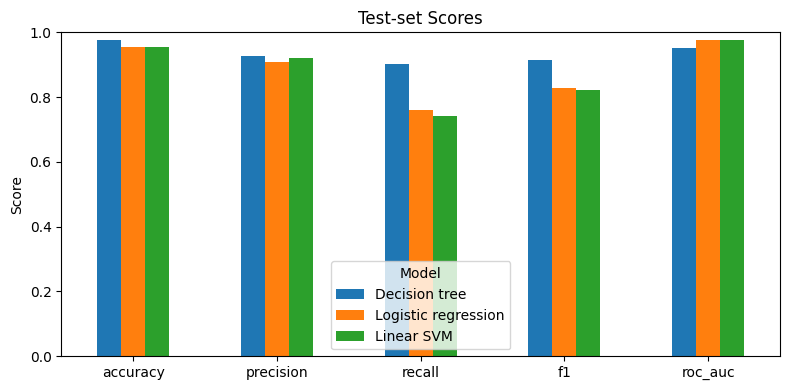

In [3]:
plt.figure(figsize=(8, 4))

comparison.plot(kind="bar", ax=plt.gca())

plt.title("Test-set Scores")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(title="Model")
plt.tight_layout()
plt.show()


Looking at the test scores, I would go with the decision tree. It gets about 0.976 accuracy, so it does get past the paper's 96%. Phishing recall is about 0.903 and F1 is about 0.915, which is better than the other two. ROC AUC is only about 0.952, and the paper is above 0.99, so we are still short there.

Logistic regression and the SVM look pretty similar to each other. Their ROC AUC is about 0.976, which is closer to the paper, but they only catch about 76% and 74% of the phishing URLs. So they miss a lot more.

The metrics I care about most are phishing recall and F1. About 86% of the URLs are benign, so accuracy can look fine even if the model misses phishing sites. Missing a phishing site is the worse mistake, so that is what I am looking at. ROC AUC is still useful because it shows the ranking and not just one cutoff.

We also only used the numeric URL features. The paper gets some of that 0.99 AUC from a MiniLM embedding model, so I did not really expect these three to match that.
